# SIT720 Task 4.1P - Clustering and PCA

**Student name:** Zenith Anthony  
**Student ID:** s225534396

**Purpose:** Complete Part B of the assessment using the Obesity dataset and the UCI Gene Expression Cancer RNA-Seq dataset.

> Academic integrity: The assessment brief permits GenAI for planning, brainstorming and editing, but requires the final submission to demonstrate your own understanding. Review, run and modify this notebook before submission, and acknowledge your actual GenAI use.


## 0. Imports and helper functions

In [1]:
from pathlib import Path
import os, tarfile, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score, v_measure_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)

def find_file(filename):
    candidates = [Path(filename), Path('/mnt/data')/filename]
    for p in candidates:
        if p.exists():
            return p
    for p in Path('.').rglob(filename):
        return p
    return None


## 1. Data preparation and encoding - Obesity dataset

The class label `NObeyesdad` is removed from the feature set. Binary categories are encoded as 0/1, `CAEC` and `CALC` are ordinal frequency variables encoded in their natural order, and nominal transport mode (`MTRANS`) is one-hot encoded. All resulting features are standardized before distance-based clustering so variables measured on larger numerical scales do not dominate Euclidean distance.

In [2]:
obesity_path = find_file('ObesityDataSet_raw_and_data_sinthetic.csv')
if obesity_path is None:
    raise FileNotFoundError('Place ObesityDataSet_raw_and_data_sinthetic.csv beside this notebook.')

df = pd.read_csv(obesity_path)
print('Dataset shape:', df.shape)
print('Total missing values:', int(df.isna().sum().sum()))
print('Class counts:')
print(df['NObeyesdad'].value_counts())

X_raw = df.drop(columns='NObeyesdad').copy()
y_raw = df['NObeyesdad'].copy()
X = X_raw.copy()

X['Gender'] = X['Gender'].map({'Female': 0, 'Male': 1})
for c in ['family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC']:
    X[c] = X[c].map({'no': 0, 'yes': 1})

ordinal_map = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
X['CAEC'] = X['CAEC'].map(ordinal_map)
X['CALC'] = X['CALC'].map(ordinal_map)
X = pd.get_dummies(X, columns=['MTRANS'], dtype=int)

print()
print('Encoded shape:', X.shape)
print()
print('Encoded values (first 5 rows):')
display(X.head())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
print()
print('Class names:', list(label_encoder.classes_))

Dataset shape: (2111, 17)
Total missing values: 0
Class counts:
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

Encoded shape: (2111, 20)

Encoded values (first 5 rows):


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,0,21.0,1.62,64.0,1,0,2.0,3.0,1,0,2.0,0,0.0,1.0,0,0,0,0,1,0
1,0,21.0,1.52,56.0,1,0,3.0,3.0,1,1,3.0,1,3.0,0.0,1,0,0,0,1,0
2,1,23.0,1.80,77.0,1,0,2.0,3.0,1,0,2.0,0,2.0,1.0,2,0,0,0,1,0
3,1,27.0,1.80,87.0,0,0,3.0,3.0,1,0,2.0,0,2.0,0.0,2,0,0,0,0,1
4,1,22.0,1.78,89.8,0,0,2.0,1.0,1,0,2.0,0,0.0,0.0,1,0,0,0,1,0



Class names: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


### Encoding design note

One-hot encoding avoids imposing an artificial numerical order on transport categories. Ordinal encoding is used only where the categories represent increasing frequency. A different choice (for example, one-hot encoding all categorical variables) would change the Euclidean geometry and therefore can change centroid locations and cluster membership.

## 2. Determine the optimal number of clusters with the Silhouette Coefficient

,k,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI_vs_class,NMI_vs_class,Inertia
0,2,0.2250,275.5158,2.3051,0.0139,0.0414,37341.7452
1,3,0.1785,254.5300,2.3559,0.1234,0.2062,34007.5358
2,4,0.1967,232.6505,1.9766,0.1207,0.2058,31714.4676
3,5,0.1925,218.6060,1.6825,0.1197,0.1997,29833.1762
4,6,0.1221,218.1805,1.6660,0.2091,0.2904,27808.4510
5,7,0.1408,216.4826,1.6474,0.2193,0.3000,26104.5551
6,8,0.1436,220.8341,1.6329,0.2239,0.3025,24333.4035
7,9,0.1653,218.6230,1.6275,0.2245,0.2976,23045.1314
8,10,0.1688,218.3914,1.5318,0.2410,0.3173,21813.2847


Optimal k by maximum silhouette = 2
Actual number of obesity classes = 7


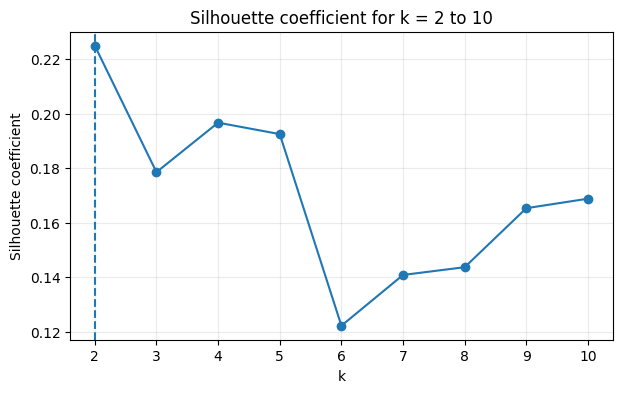

In [3]:
results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, init='k-means++', n_init=20,
                   max_iter=500, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    results.append({
        'k': k,
        'Silhouette': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labels),
        'ARI_vs_class': adjusted_rand_score(y, labels),
        'NMI_vs_class': normalized_mutual_info_score(y, labels),
        'Inertia': model.inertia_
    })

silhouette_table = pd.DataFrame(results)
display(silhouette_table.round(4))
optimal_k = int(silhouette_table.loc[silhouette_table['Silhouette'].idxmax(), 'k'])
print('Optimal k by maximum silhouette =', optimal_k)
print('Actual number of obesity classes =', y_raw.nunique())

plt.figure(figsize=(7,4))
plt.plot(silhouette_table['k'], silhouette_table['Silhouette'], marker='o')
plt.axvline(optimal_k, linestyle='--')
plt.xticks(silhouette_table['k'])
plt.xlabel('k')
plt.ylabel('Silhouette coefficient')
plt.title('Silhouette coefficient for k = 2 to 10')
plt.grid(alpha=.25)
plt.show()

**Interpretation for this dataset:** the maximum silhouette is expected at `k=2` (about 0.225), whereas the supplied target contains seven obesity classes. This difference is reasonable because K-Means uses only feature-space distances and does not know the clinical/class labels. The seven labels need not form seven compact, spherical, equally separated regions in the encoded feature space.

## 3. K-Means versus K-Means++

To isolate the effect of initialization, both models use one initialization (`n_init=1`) and the same random seed. `init='random'` represents conventional random centroid selection; `init='k-means++'` spreads the starting centers more deliberately.

In [4]:
comparison = []
q3_labels = {}
for name, init in [('K-Means (random init)', 'random'), ('K-Means++', 'k-means++')]:
    model = KMeans(n_clusters=optimal_k, init=init, n_init=1,
                   max_iter=500, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    q3_labels[name] = labels
    comparison.append({
        'Method': name,
        'Silhouette': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labels),
        'ARI': adjusted_rand_score(y, labels),
        'NMI': normalized_mutual_info_score(y, labels),
        'Inertia': model.inertia_,
        'Iterations': model.n_iter_
    })
q3_table = pd.DataFrame(comparison)
display(q3_table.round(4))

,Method,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI,NMI,Inertia,Iterations
0,K-Means (random init),0.1456,213.4678,2.8711,0.0956,0.1681,38339.3813,7
1,K-Means++,0.1594,213.9707,2.8451,0.0934,0.1767,38331.0819,12


**Interpretation:** with seed 42, K-Means++ gives a slightly higher silhouette and NMI and slightly lower inertia/Davies-Bouldin than random initialization. The difference is small, demonstrating that K-Means++ often improves the starting configuration but does not guarantee a better final solution for every metric or every run.

## 4. Stability analysis over 50 random initializations

Seed          Silhouette         Calinski-Harabasz  \
                       mean      std       mean     std              mean   
Method                                                                      
K-Means (random init)  24.5  14.5774     0.2227  0.0973          217.2948   
K-Means++              24.5  14.5774     0.2180  0.0952          220.6586   

                               Davies-Bouldin             ARI             NMI  \
                           std           mean     std    mean     std    mean   
Method                                                                          
K-Means (random init)  52.4909         2.3528  0.5874  0.0474  0.0412  0.0983   
K-Means++              52.2488         2.3520  0.5705  0.0442  0.0397  0.0930   

                                  Inertia            
                          std        mean       std  
Method                                               
K-Means (random init)  0.0721  38295.6985  876.5188  
K-Means++              0.0704  38240.1947  871.1618

/tmp/ipykernel_787/2591378357.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([


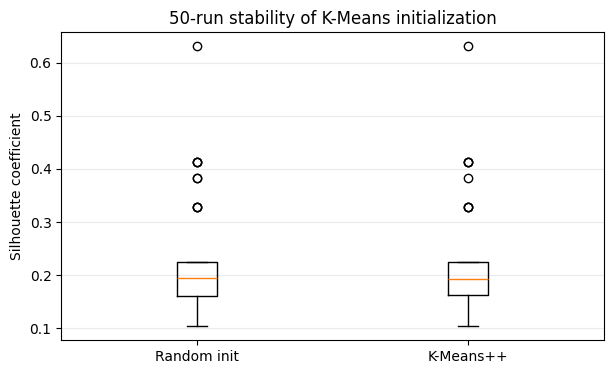

In [5]:
runs = []
for name, init in [('K-Means (random init)', 'random'), ('K-Means++', 'k-means++')]:
    for seed in range(50):
        model = KMeans(n_clusters=optimal_k, init=init, n_init=1,
                       max_iter=500, random_state=seed)
        labels = model.fit_predict(X_scaled)
        runs.append({
            'Method': name, 'Seed': seed,
            'Silhouette': silhouette_score(X_scaled, labels),
            'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels),
            'Davies-Bouldin': davies_bouldin_score(X_scaled, labels),
            'ARI': adjusted_rand_score(y, labels),
            'NMI': normalized_mutual_info_score(y, labels),
            'Inertia': model.inertia_
        })

runs_df = pd.DataFrame(runs)
summary = runs_df.groupby('Method').agg(['mean','std'])
display(summary.round(4))

plt.figure(figsize=(7,4))
plt.boxplot([
    runs_df.loc[runs_df['Method']=='K-Means (random init)','Silhouette'],
    runs_df.loc[runs_df['Method']=='K-Means++','Silhouette']
], labels=['Random init','K-Means++'])
plt.ylabel('Silhouette coefficient')
plt.title('50-run stability of K-Means initialization')
plt.grid(axis='y', alpha=.25)
plt.show()

**Interpretation:** the standard deviations quantify sensitivity to initialization. On this dataset, K-Means++ has slightly lower average inertia but broadly similar variability to random initialization when each run uses only one start. Therefore K-Means++ is useful but is not a substitute for multiple restarts (`n_init > 1`) when reliability is important.

## 5. DBSCAN on the Obesity dataset

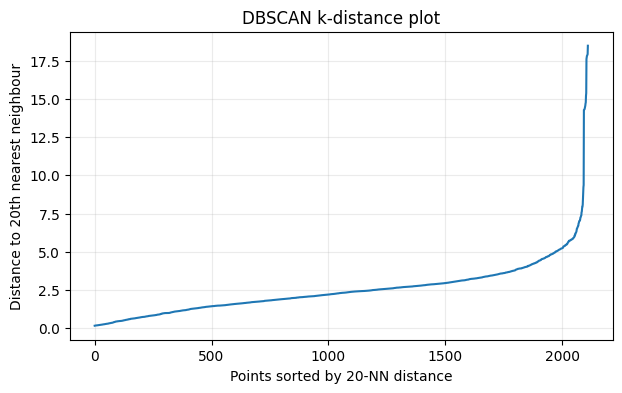

eps = 6.0 min_samples = 20
DBSCAN clusters: 3
Noise points: 29 (1.37%)
Silhouette excluding noise: 0.3939
ARI vs classes: 0.0027
NMI vs classes: 0.0323
Cluster sizes: {np.int64(-1): np.int64(29), np.int64(0): np.int64(1996), np.int64(1): np.int64(51), np.int64(2): np.int64(35)}


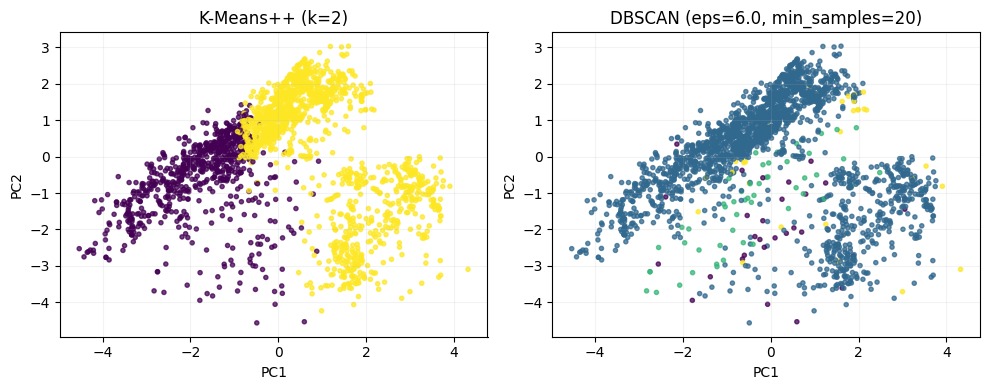

In [6]:
# min_samples heuristic: approximately the number of encoded dimensions.
min_samples = X.shape[1]   # 20
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(7,4))
plt.plot(k_distances)
plt.xlabel('Points sorted by 20-NN distance')
plt.ylabel('Distance to 20th nearest neighbour')
plt.title('DBSCAN k-distance plot')
plt.grid(alpha=.25)
plt.show()

# The elbow in this dataset is around 6, so use eps=6.0.
eps = 6.0
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
db_labels = dbscan.fit_predict(X_scaled)
non_noise = db_labels != -1
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
noise_count = int((db_labels == -1).sum())

print('eps =', eps, 'min_samples =', min_samples)
print('DBSCAN clusters:', n_clusters)
print('Noise points:', noise_count, f'({100*noise_count/len(db_labels):.2f}%)')
if n_clusters >= 2:
    print('Silhouette excluding noise:', round(silhouette_score(X_scaled[non_noise], db_labels[non_noise]), 4))
print('ARI vs classes:', round(adjusted_rand_score(y, db_labels), 4))
print('NMI vs classes:', round(normalized_mutual_info_score(y, db_labels), 4))
print('Cluster sizes:', dict(zip(*np.unique(db_labels, return_counts=True))))

# 2D PCA is used only to visualise the cluster shapes.
vis_pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_vis = vis_pca.fit_transform(X_scaled)
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(X_vis[:,0], X_vis[:,1], c=q3_labels['K-Means++'], s=9, alpha=.75)
axes[0].set_title(f'K-Means++ (k={optimal_k})')
axes[1].scatter(X_vis[:,0], X_vis[:,1], c=db_labels, s=9, alpha=.75)
axes[1].set_title(f'DBSCAN (eps={eps}, min_samples={min_samples})')
for ax in axes:
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.grid(alpha=.15)
plt.tight_layout(); plt.show()

**Interpretation:** with `eps=6.0` and `min_samples=20`, DBSCAN identifies three dense groups and a small set of noise points (about 1.4%). Its external agreement with the seven supplied labels is weak, but it provides something K-Means cannot: explicit outlier/noise detection and clusters that need not be centroid-shaped. The dominant DBSCAN cluster also shows that density structure in this encoded space is highly imbalanced.

# Gene Expression dataset - Questions 6-8

Questions 6-8 use the **UCI Gene Expression Cancer RNA-Seq** dataset supplied with this task.  
The dataset contains 801 tumour samples, 20,531 gene-expression features and five class labels
(BRCA, COAD, KIRC, LUAD and PRAD). The sample identifier is removed before analysis and the
gene features are standardized before PCA and K-Means.


In [7]:
def find_gene_files():
    search_roots = [Path('.'), Path('/mnt/data')]

    # 1) Look for already extracted files.
    for root in search_roots:
        direct_data = root/'data.csv'
        direct_labels = root/'labels.csv'
        if direct_data.exists() and direct_labels.exists():
            return direct_data, direct_labels

        folder = root/'TCGA-PANCAN-HiSeq-801x20531'
        if (folder/'data.csv').exists() and (folder/'labels.csv').exists():
            return folder/'data.csv', folder/'labels.csv'

    # 2) Recursive fallback.
    for root in search_roots:
        for data_path in root.rglob('data.csv'):
            label_path = data_path.parent/'labels.csv'
            if label_path.exists() and 'PANCAN' in str(data_path).upper():
                return data_path, label_path

    # 3) If only the supplied ZIP exists, extract ZIP -> TAR.GZ -> data.csv/labels.csv.
    zip_candidates = [
        Path('/mnt/data/gene+expression+cancer+rna+seq.zip'),
        Path('gene+expression+cancer+rna+seq.zip')
    ]
    for zip_path in zip_candidates:
        if zip_path.exists():
            extract_root = Path('/mnt/data/gene_expression_extracted')
            extract_root.mkdir(parents=True, exist_ok=True)

            with zipfile.ZipFile(zip_path, 'r') as zf:
                zf.extractall(extract_root)

            tar_path = extract_root/'TCGA-PANCAN-HiSeq-801x20531.tar.gz'
            if tar_path.exists():
                with tarfile.open(tar_path, 'r:gz') as tf:
                    tf.extractall(extract_root)

            folder = extract_root/'TCGA-PANCAN-HiSeq-801x20531'
            if (folder/'data.csv').exists() and (folder/'labels.csv').exists():
                return folder/'data.csv', folder/'labels.csv'

    return None, None

gene_data_path, gene_labels_path = find_gene_files()
gene_available = gene_data_path is not None
print('Gene data available:', gene_available)
if gene_available:
    print('Data file:', gene_data_path)
    print('Labels file:', gene_labels_path)
else:
    print('Gene-expression files were not found.')


Gene data available: True
Data file: gene_expr/TCGA-PANCAN-HiSeq-801x20531/data.csv
Labels file: gene_expr/TCGA-PANCAN-HiSeq-801x20531/labels.csv


## 6. PCA to three principal components and 3D visualisation

The sample-ID column is removed and all 20,531 gene features are standardized. PCA is then
fitted with three components. The 3D plot is coloured using the supplied tumour labels only
for interpretation; the labels are not used to calculate the principal components.


Gene feature matrix: (801, 20531)
Labels: {'BRCA': 300, 'KIRC': 146, 'LUAD': 141, 'PRAD': 136, 'COAD': 78}
Missing values: 0


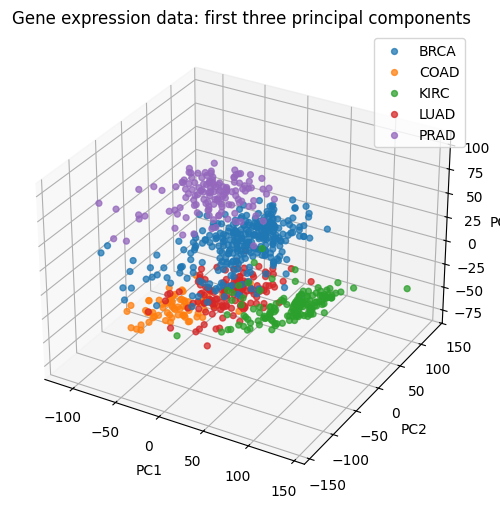

In [8]:
if gene_available:
    gene_df = pd.read_csv(gene_data_path)
    labels_df = pd.read_csv(gene_labels_path)

    # UCI files include a sample-id column; remove it from the feature matrix.
    gene_X = gene_df.drop(columns=[gene_df.columns[0]]) if gene_df.columns[0].lower().startswith('unnamed') or gene_df.columns[0].upper().startswith('SAMPLE') else gene_df.copy()
    if gene_X.shape[1] > 20531:
        gene_X = gene_X.iloc[:, -20531:]

    # labels.csv normally contains sample + Class.
    class_col = 'Class' if 'Class' in labels_df.columns else labels_df.columns[-1]
    gene_y_raw = labels_df[class_col].astype(str)
    gene_le = LabelEncoder()
    gene_y = gene_le.fit_transform(gene_y_raw)

    print('Gene feature matrix:', gene_X.shape)
    print('Labels:', gene_y_raw.value_counts().to_dict())
    print('Missing values:', int(gene_X.isna().sum().sum()))

    gene_scaler = StandardScaler()
    gene_X_scaled = gene_scaler.fit_transform(gene_X)

    pca3 = PCA(n_components=3, random_state=RANDOM_STATE)
    gene_pcs = pca3.fit_transform(gene_X_scaled)
    gene_pc_df = pd.DataFrame(gene_pcs, columns=['PC1','PC2','PC3'])
    gene_pc_df['Class'] = gene_y_raw.values

    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(111, projection='3d')
    for label in gene_le.classes_:
        mask = gene_y_raw.values == label
        ax.scatter(gene_pcs[mask,0], gene_pcs[mask,1], gene_pcs[mask,2], s=18, label=label, alpha=.75)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
    ax.set_title('Gene expression data: first three principal components')
    ax.legend()
    plt.show()
else:
    print('Q6 skipped in this execution: add data.csv and labels.csv, then rerun all cells.')

## 7. Variance explained by the first three PCs

The explained-variance ratio for each component is its eigenvalue divided by the sum of the
eigenvalues of all original dimensions. The cumulative percentage shows how much total
standardized-data variance is retained by PC1-PC3 together.


,Component,Explained variance %,Cumulative variance %
0,PC1,10.540,10.540
1,PC2,8.754,19.294
2,PC3,7.810,27.104


Cumulative variance of first 3 PCs: 27.104%


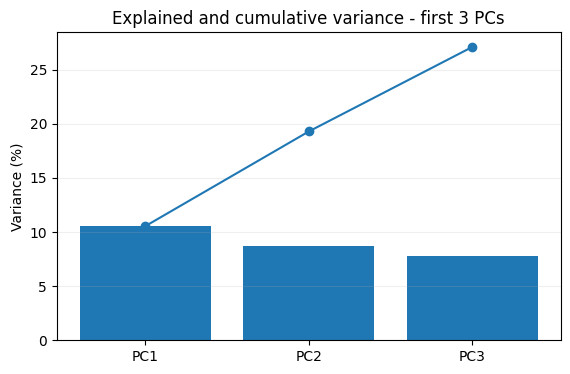

In [9]:
if gene_available:
    explained = pca3.explained_variance_ratio_
    cumulative = np.cumsum(explained)
    variance_table = pd.DataFrame({
        'Component':['PC1','PC2','PC3'],
        'Explained variance %': explained*100,
        'Cumulative variance %': cumulative*100
    })
    display(variance_table.round(3))
    print('Cumulative variance of first 3 PCs:', f'{cumulative[-1]*100:.3f}%')

    plt.figure(figsize=(6.5,4))
    plt.bar(['PC1','PC2','PC3'], explained*100)
    plt.plot(['PC1','PC2','PC3'], cumulative*100, marker='o')
    plt.ylabel('Variance (%)')
    plt.title('Explained and cumulative variance - first 3 PCs')
    plt.grid(axis='y', alpha=.2)
    plt.show()
else:
    print('Q7 skipped in this execution because the gene dataset is not present.')

The explained-variance ratio for component *i* is its eigenvalue divided by the sum of eigenvalues across all original dimensions. A low cumulative percentage means three PCs are useful for visualisation but do not retain most of the original information; this matters when deciding whether to cluster only in 3D.

## 8. K-Means on original gene features versus three-PC representation

,Representation,ARI,NMI,Homogeneity,Completeness,V-measure
0,Original standardized genes,0.7941,0.8539,0.8610,0.8469,0.8539
1,First 3 PCs,0.6060,0.6726,0.6887,0.6573,0.6726


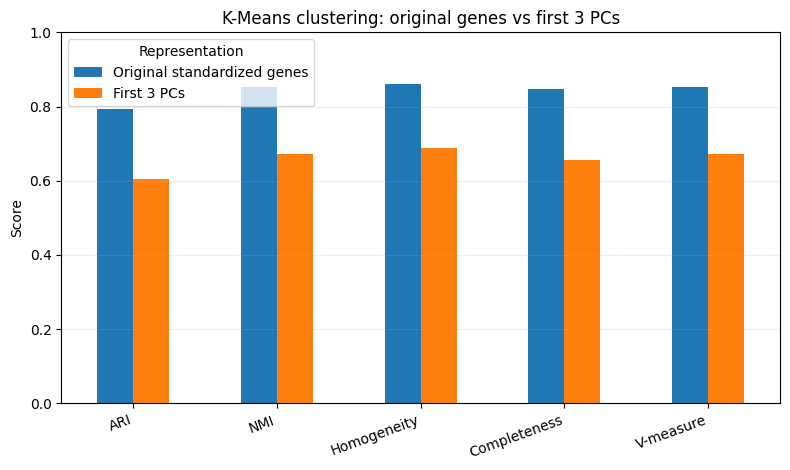

Original-feature cluster contingency table


col_0,0,1,2,3,4
Class,,,,,
BRCA,0,0,247,0,53
COAD,74,0,0,0,4
KIRC,0,144,0,0,2
LUAD,0,0,2,0,139
PRAD,0,0,1,134,1


3-PC cluster contingency table


col_0,0,1,2,3,4
Class,,,,,
BRCA,10,59,28,0,203
COAD,0,9,69,0,0
KIRC,0,6,1,139,0
LUAD,0,120,18,1,2
PRAD,129,1,0,0,6


In [10]:
if gene_available:
    k_gene = len(np.unique(gene_y))
    rows = []
    gene_cluster_labels = {}

    for name, Z in [('Original standardized genes', gene_X_scaled), ('First 3 PCs', gene_pcs)]:
        model = KMeans(n_clusters=k_gene, init='k-means++', n_init=20,
                       max_iter=500, random_state=RANDOM_STATE)
        pred = model.fit_predict(Z)
        gene_cluster_labels[name] = pred
        rows.append({
            'Representation': name,
            'ARI': adjusted_rand_score(gene_y, pred),
            'NMI': normalized_mutual_info_score(gene_y, pred),
            'Homogeneity': homogeneity_score(gene_y, pred),
            'Completeness': completeness_score(gene_y, pred),
            'V-measure': v_measure_score(gene_y, pred)
        })

    gene_compare = pd.DataFrame(rows)
    display(gene_compare.round(4))

    ax = gene_compare.set_index('Representation')[
        ['ARI','NMI','Homogeneity','Completeness','V-measure']
    ].T.plot(kind='bar', figsize=(8, 4.8))
    plt.ylabel('Score')
    plt.ylim(0, 1)
    plt.title('K-Means clustering: original genes vs first 3 PCs')
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=.2)
    plt.tight_layout()
    plt.show()

    print('Original-feature cluster contingency table')
    display(pd.crosstab(gene_y_raw, gene_cluster_labels['Original standardized genes']))

    print('3-PC cluster contingency table')
    display(pd.crosstab(gene_y_raw, gene_cluster_labels['First 3 PCs']))
else:
    print('Q8 skipped in this execution because the gene dataset is not present.')


**Interpretation:** the original standardized gene space gives substantially better agreement
with the supplied tumour labels than the three-PC representation. The first three PCs provide
a useful visual summary, but they retain only about 27% of total variance, so reducing to three
dimensions discards information that is useful for clustering. PCA is therefore useful here for
visualisation, but three components are too aggressive to recommend as the sole preprocessing
representation for K-Means if clustering accuracy is the priority.


## Generative AI acknowledgement

I used ChatGPT (OpenAI) to assist with planning the analysis, generating and debugging Python
code, interpreting the numerical outputs, and editing the report for clarity. The numerical
results and figures reported here were produced by executing the notebook on the supplied
Obesity dataset and the UCI Gene Expression Cancer RNA-Seq dataset. I used the GenAI output
as support for completing the analysis and understanding the methods rather than as a substitute
for the required machine-learning work.
